In [5]:
print("Let's Start")

Let's Start


In [13]:
from sklearn.datasets import make_regression

x , y = make_regression(n_samples=500 , n_features=10 , noise=1 , random_state=42)
x.shape , y.shape

((500, 10), (500,))

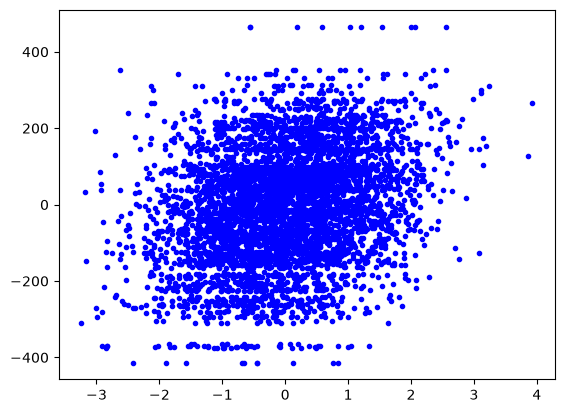

In [14]:
import matplotlib.pyplot as plt

plt.plot(x , y, 'b.')
plt.show()

In [15]:
from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test = train_test_split(x , y, test_size=0.2 , random_state=42)

Using basic LinearRegreesion

In [16]:
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import r2_score
lr = SGDRegressor(penalty='l2' , max_iter=500 , eta0=0.1 , learning_rate='constant' , alpha=0.001)
lr.fit(x_train , y_train)
lr_pred = lr.predict(x_test)
lr_score = r2_score(y_test , lr_pred)
print(lr_score)
print(lr.coef_ , lr.intercept_)
print("Training Score : " , lr.score(x_train , y_train))
print("Testing Score : " , lr.score(x_test , y_test))

0.9998299429111062
[41.29238692 65.547728   19.35994205 46.06629595 25.33259529 16.96454906
 81.93642287 64.59836346  6.58442576 28.36278948] [-0.44562227]
Training Score :  0.9998417888989348
Testing Score :  0.9998299429111062


Using Ridge of sklearn

In [10]:
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=0.001 , solver='sparse_cg')
ridge.fit(x_train , y_train)
ridge_pred = ridge.predict(x_test)
ridge_score = r2_score(y_test , ridge_pred)
print(ridge_score)
print(ridge.coef_ , ridge.intercept_)
print("Training Score : " , ridge.score(x_train , y_train))
print("Testing Score : " , ridge.score(x_test , y_test))

0.9999508872066837
[41.78627944 65.01276729 18.97542905 46.14255725 24.67771438 16.79368551
 82.48638446 64.49648747  7.33969083 28.64408785] -0.03127535203693377
Training Score :  0.9999571660186138
Testing Score :  0.9999508872066837


Using MYRidgeCLass

In [19]:
import numpy as np
class MyRidge:

    def __init__(self , alpha=1 , lr_ =0.1 , epochs=10):
        self.alpha = alpha
        self.coef_ = None
        self.intercept_ = None
        self.lr_ = lr_
        self.epochs = epochs

    def fit(self, x , y):
        x = np.insert(x , 0 , 1 , axis=1)
        self.coef_ = np.ones(x.shape[1])
        self.intercept_ = 0
        coef_ = np.zeros(x.shape[1])
        for i in range(self.epochs):
            loss= (np.dot(x.T , x).dot(coef_) - np.dot(x.T , y)) / x.shape[0] + self.alpha * coef_
            coef_ = coef_ - (self.lr_ * loss)

        self.coef_ = coef_[1:]
        self.intercept_  = coef_[0]
        print("Model Trained Successfully")

    def predict(self , x):
        return np.dot(x , self.coef_) + self.intercept_

In [20]:
my = MyRidge(alpha=0.001 , lr_=0.005 , epochs=500)
my.fit(x_train , y_train)
my_pred = my.predict(x_test)
my_score = r2_score(y_test , my_pred)
print(my_score)
print(my.coef_ , my.intercept_)

Model Trained Successfully
0.9912581829059545
[39.26970392 57.38152076 17.37507545 42.83792183 21.97899857 14.52366564
 76.93590048 59.43128967  7.71290182 24.64722903] 0.14090033658987366
